# **CS6155D Topics in Data Analytics - Winter 2022-23 - M. Tech Assignment**

Q.1: Create 500 points of the function given below :

f(x) = x^3 + 5*(x^2) + 7*x + 2

Assume x takes values in the range (-4, 2). Plot the points generated.

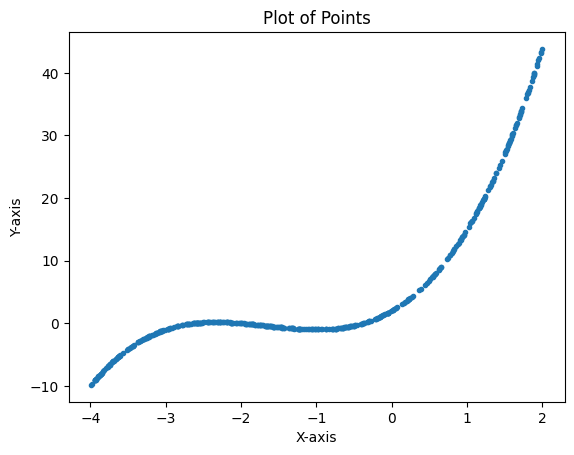

In [372]:
import random
import matplotlib.pyplot as plt
import numpy as np

x_points=[]
y_points=[]

def generateY(x):
    return x**3 + 5*(x**2) + 7*x + 2

def createPoints():
    x = random.uniform(-4, 2) #generating x value in the given range
    x_points.append(x)
    y = generateY(x) #computing y value for the given x
    y_points.append(y)

for i in range(500):
    createPoints()

plt.plot(x_points, y_points, '.')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Plot of Points')
plt.show()

Q.2: Add random noise to 30% of the above 500 points, selected at random. 

Assume that random noise follow a Gaussian distribution. Plot the points after adding the noise.


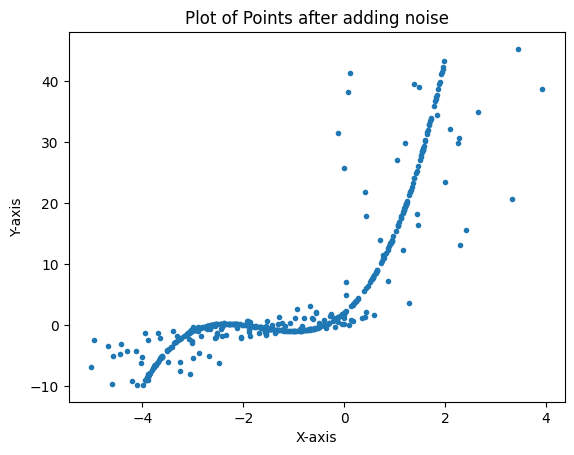

In [373]:
import random
import matplotlib.pyplot as plt


# 30% in 500 is 150.

def generateNoise(): #generates noise
    return random.gauss(0,1)

def addNoise(i):  
    noise = generateNoise()
    x_points[i] += noise
    y_points[i] += noise

indices_to_add_noise = random.sample(range(500), 150) #generate 150 random indices

for index in indices_to_add_noise:
    addNoise(index)

plt.plot(x_points, y_points,".")
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Plot of Points after adding noise')
plt.show()

Q.3: Divide the points in Q.2 in 80:20 way to obtain Train set and Test set.

Fit a Linear regression model for the points in the Train set. Create you own function without using
built-in function of Linear regression. Use the gradient descent method

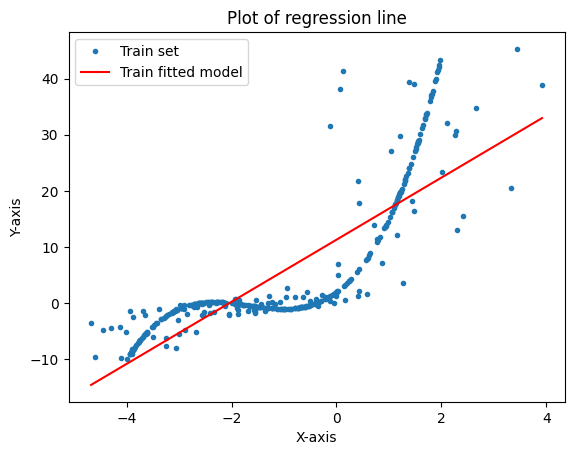

In [374]:
import numpy as np
import matplotlib.pyplot as plt

Train_setx=[]
Train_sety=[]

Test_setx=[]
Test_sety=[]

indices_for_train_set = random.sample(range(500), 400)

for i in range(500):
    if i in indices_for_train_set:
        Train_setx.append(x_points[i])
        Train_sety.append(y_points[i])
    else:
        Test_setx.append(x_points[i])
        Test_sety.append(y_points[i])

X = np.array(Train_setx)
Y = np.array(Train_sety)

def plotter(X,Y,Y_pred):
    plt.plot(X, Y,".",label="Train set")
    plt.plot([min(X),max(X)],[min(Y_pred),max(Y_pred)],color="red",label="Train fitted model")
    plt.xlabel('X-axis')
    plt.ylabel('Y-axis')
    plt.title('Plot of regression line')
    plt.legend()
    plt.show()

def linearRegression(Y_pred,m,c,L,epochs,X,Y,n):
    for i in range(epochs):
        Y_pred = m*X + c
        D_m = (-2/n)*sum(X*(Y - Y_pred))
        D_c = (-2/n)*sum(Y - Y_pred)
        m = m - L*D_m
        c = c - L*D_c
        # plotter(X,Y,Y_pred)
    return Y_pred,m,c

m=0
c=0

L=0.1
epochs=1000

Y_pred=np.zeros(X.shape)


Y_pred,m,c = linearRegression(Y_pred,m,c,L,epochs,X,Y,len(X))

Y_pred = m*X + c

plotter(X,Y,Y_pred)

Q.4: Report the Train error and Test error. Plot the fitted model also

Train Error: 48.73138187427719
Test Error: 36.15944848867233


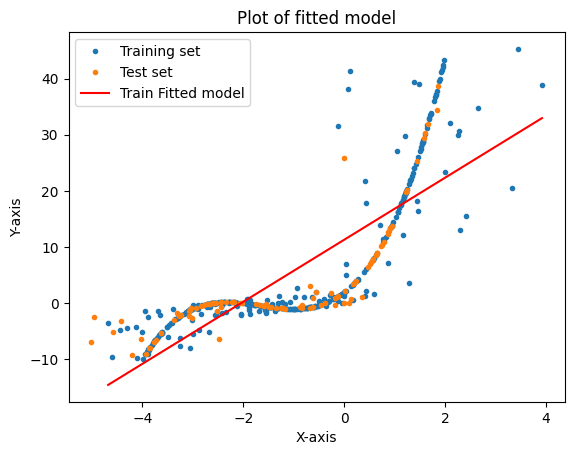

In [375]:

X_T = np.array(Test_setx)
Y_T = np.array(Test_sety)

# Evaluate the model on the train set
train_mse = (1/len(X)) * sum((Y - Y_pred)**2)

# Evaluate the model on the test set
Y_Test_Pred = np.zeros(X_T.shape)
mY,cY=0,0
Y_Test_Pred, mY, cY = linearRegression(Y_Test_Pred,mY,cY,L,epochs,X_T,Y_T,len(X_T))

test_mse = (1/len(X_T)) * sum((Y_T - Y_Test_Pred)**2)

print("Train Error:", train_mse)
print("Test Error:", test_mse)

#Plot
plt.plot(X, Y, '.', label='Training set')
plt.plot(X_T, Y_T, '.', label='Test set')
plt.plot([min(X),max(X)],[min(Y_pred),max(Y_pred)],color="red",label='Train Fitted model')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Plot of fitted model')
plt.legend()
plt.show()

Q.5: Fit a quadratic and cubic models and compare the Test error rates with that in Q.4. Which model is
the best one? Is your best model close to the original equation used for creating the data in Q.1?


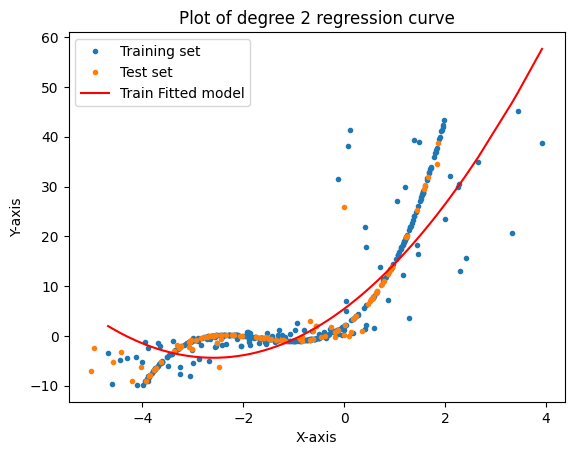

Train Error: 35.638752503183184
Test Error: 25.092410908385673


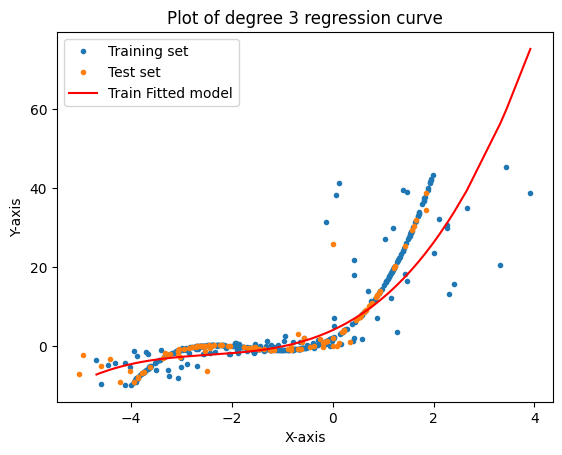

Train Error: 38.99040571409919
Test Error: 12.82138184071253


In [376]:
def plotter(X_train, Y_train, X_test, Y_test, Y_train_pred, Y_test_pred, degree):
    plt.plot(X_train, Y_train, '.', label='Training set')
    plt.plot(X_test, Y_test, '.', label='Test set')
    plt.plot(np.sort(X_train), Y_train_pred[np.argsort(X_train)], color="red", label="Train Fitted model")
    # plt.plot(np.sort(X_test), Y_test_pred[np.argsort(X_test)], color="green", label="Test")
    plt.xlabel('X-axis')
    plt.ylabel('Y-axis')
    plt.title(f'Plot of degree {degree} regression curve')
    plt.legend()
    plt.show()
    

#Quadratic function

def linearRegression_2(Y_pred,k,m,c,L,epochs,X,Y,n):
    X2=X**2
    for i in range(epochs):
        Y_pred = k*X2 + m*X + c
        D_k = (-2/n)*sum(X2*(Y - Y_pred))
        D_m = (-2/n)*sum(X*(Y - Y_pred))
        D_c = (-2/n)*sum(Y - Y_pred)
        k= k - L*D_k
        m = m - L*D_m
        c = c - L*D_c
        # plotter(X,Y,Y_pred)
    return Y_pred,k,m,c

m=0
c=0
k=0
L=0.001
epochs=1000


Y_pred=np.zeros(X.shape)

Y_pred,k,m,c = linearRegression_2(Y_pred,k,m,c,L,epochs,X,Y,len(X))

Y_pred = k*(X**2) + m*X + c



X_T = np.array(Test_setx)
Y_T = np.array(Test_sety)

# Evaluate the model on the train set
train_mse = (1/len(X)) * sum((Y - Y_pred)**2)

# Evaluate the model on the test set
Y_T_Pred = np.zeros(X_T.shape)

kY,mY,cY=0,0,0
Y_T_Pred,kY, mY, cY = linearRegression_2(Y_T_Pred,kY,mY,cY,L,epochs,X_T,Y_T,len(X_T))

Y_T_Pred = kY*(X_T**2) + mY*X_T + cY

test_mse = (1/len(X_T)) * sum((Y_T - Y_T_Pred)**2)



plotter(X, Y, X_T, Y_T, Y_pred, Y_T_Pred, 2)



print("Train Error:", train_mse)
print("Test Error:", test_mse)

#Cubic function

def linearRegression_3(Y_pred,p,k,m,c,L,epochs,X,Y,n):
    X3=X**3
    X2=X**2
    for i in range(epochs):
        Y_pred = p*X3 + k*X2 + m*X + c
        D_p = (-2/n)*sum(X3*(Y - Y_pred))
        D_k = (-2/n)*sum(X2*(Y - Y_pred))
        D_m = (-2/n)*sum(X*(Y - Y_pred))
        D_c = (-2/n)*sum(Y - Y_pred)
        p = p - L*D_p
        k= k - L*D_k
        m = m - L*D_m
        c = c - L*D_c
        # plotter(X,Y,Y_pred)
    return Y_pred,p,k,m,c

m=0
c=0
k=0
p=0
L=0.001
epochs=1000


Y_pred=np.zeros(X.shape)

Y_pred,p,k,m,c = linearRegression_3(Y_pred,p,k,m,c,L,epochs,X,Y,len(X))

Y_pred = p*(X**3) +  k*(X**2) + m*X + c



X_T = np.array(Test_setx)
Y_T = np.array(Test_sety)

# Evaluate the model on the train set
train_mse = (1/len(X)) * sum((Y - Y_pred)**2)

# Evaluate the model on the test set
Y_T_Pred = np.zeros(X_T.shape)

pY,kY,mY,cY=0,0,0,0
Y_T_Pred,pY,kY, mY, cY = linearRegression_3(Y_T_Pred,pY,kY,mY,cY,L,epochs,X_T,Y_T,len(X_T))

Y_T_Pred = pY*(X_T**3) + kY*(X_T**2) + mY*X_T + cY

test_mse = (1/len(X_T)) * sum((Y_T - Y_T_Pred)**2)



plotter(X, Y, X_T, Y_T, Y_pred, Y_T_Pred, 3)
print("Train Error:", train_mse)
print("Test Error:", test_mse)



Q.6: Assume that all the points with x value less than 0 belongs to Class 1 and rest of the points belongs
to Class 2. Let Blue colour represents Class 1 points and Red colour represents Class 2 points. Plot the
points

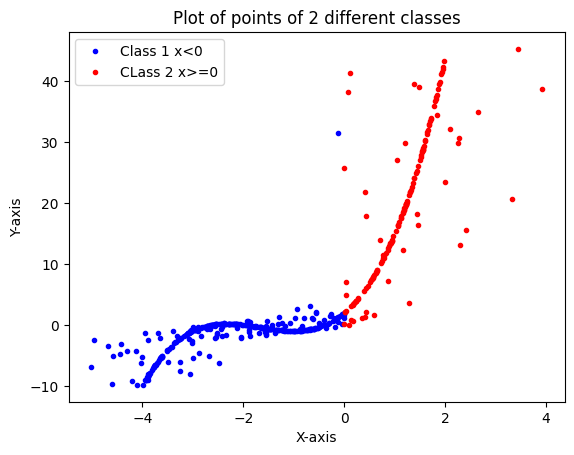

In [377]:
Xp = np.array(x_points)
Yp = np.array(y_points)

class1_x = Xp[Xp<0]
class1_y = Yp[Xp<0]
class2_x = Xp[Xp>=0]
class2_y = Yp[Xp>=0]

plt.plot(class1_x, class1_y, '.', color="blue",label='Class 1 x<0')
plt.plot(class2_x, class2_y, '.', color="red",label='CLass 2 x>=0')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Plot of points of 2 different classes')
plt.legend()
plt.show()

Q.7: Build a Logistic regression model of classification for the above case and draw the decision boundary
also. Report the confusion matrix for the Test set. Create your own function for Logistic regression.

Confusion Matrix:
[[66  1]
 [ 2 31]]


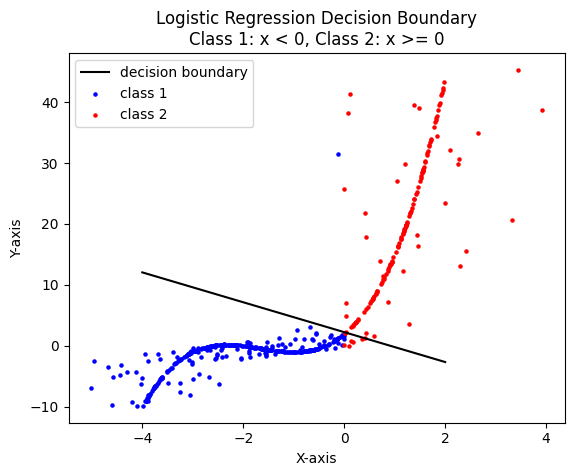

In [378]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix


x_vals = Xp

# Generate the corresponding y values
y_vals = Yp

# Define the class labels
class_labels = np.where(x_vals < 0, 1, 2)

# Combine features and labels into a single dataset
data = np.column_stack((x_vals, y_vals, class_labels))

# Split dataset into training and testing sets
train_split = int(0.8 * len(data))
train_data = data[:train_split]
test_data = data[train_split:]

# Separate features and labels for training set
X_train = train_data[:, :2]
y_train = train_data[:, 2]

# Separate features and labels for testing set
X_test = test_data[:, :2]
y_test = test_data[:, 2]

# Create logistic regression object
lr = LogisticRegression()

# Train the model on the training data
lr.fit(X_train, y_train)

# Predict labels for the testing data
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:, 1]  

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Print confusion matrix
print("Confusion Matrix:")
print(cm)

# Compute decision boundary
w = lr.coef_[0]
a = -w[0] / w[1]
xx = np.linspace(-4, 2)
yy = a * xx - (lr.intercept_[0]) / w[1]

# Plot the decision boundary and scatter plot of points
plt.plot(xx, yy, 'k-', label='decision boundary')
plt.scatter(class1_x, class1_y, c='blue', s=5, label='class 1')
plt.scatter(class2_x, class2_y, c='red', s=5, label='class 2')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Logistic Regression Decision Boundary\nClass 1: x < 0, Class 2: x >= 0')
plt.legend()
plt.show()

Q.8: Plot the ROC curve and find the AUC also.

AUC= 0.9873360470375395


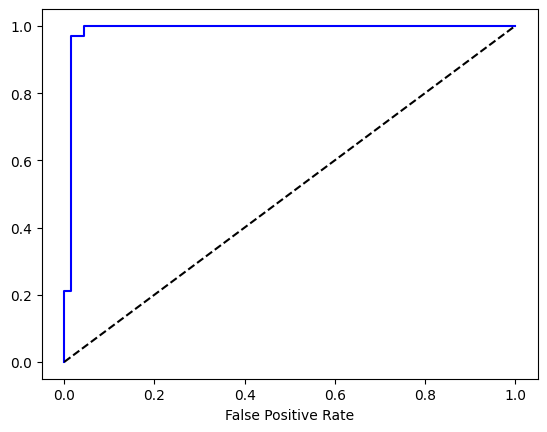

In [379]:
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label=2)
roc_auc = auc(fpr, tpr)

# Plot ROC curve and print AUC
plt.plot(fpr, tpr, 'b-', label='ROC curve (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel
print("AUC=",roc_auc)